In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import ast
from collections import Counter
from torch.utils.data import Dataset, DataLoader
import time
from tqdm import tqdm

In [ ]:
df = pd.read_csv("/kaggle/input/datasets/deelipsolanki/tokenized-data/process_data.csv")
df.head()

,text,processed
0,They do not!,"['they', 'do', 'not']"
1,They do to!,"['they', 'do', 'to']"
2,I hope so.,"['i', 'hope', 'so']"
3,She okay?,"['she', 'okay']"
4,Let's go.,"[""let's"", 'go']"


In [4]:
df['processed'][0]

"['they', 'do', 'not']"

In [5]:
# convert them to lists
df['processed'] = df['processed'].apply(ast.literal_eval)
df['processed'][0]

['they', 'do', 'not']

In [6]:
def count_length(x):
  return len(x)

In [7]:
df['length'] = df['processed'].map(count_length)

In [8]:
np.quantile(df['length'], [0.8, 0.9, 0.95, 0.99])

array([ 9., 12., 16., 25.])

- 99% of sentences have length <= 25

In [10]:
df['length'].median()

5.0

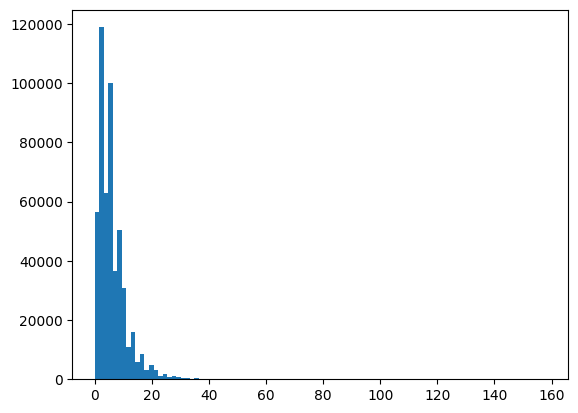

In [11]:
import matplotlib.pyplot as plt

plt.hist(df['length'], bins = 100)
plt.show()

In [12]:
new_df = df[ df['length'] <= 25 ]
new_df.shape

(511443, 3)

In [13]:
sentences = []
tokens = []
for sent in new_df['processed'].values:
  if len(sent) > 1:  # only use sentences with more than 1 token
      sentences.append(sent)
      tokens.extend(sent)
len(sentences), len(tokens)

(454892, 2967590)

In [14]:
sentences[:3]

[['they', 'do', 'not'], ['they', 'do', 'to'], ['i', 'hope', 'so']]

In [15]:
# build vocab
vocab = {'<unk>':0}

for token in Counter(tokens).keys():
  if token not in vocab:
    vocab[token] = len(vocab)

In [16]:
len(vocab)

64649

In [17]:
import json

with open('vocab.json', 'w') as file:
    json.dump(vocab, file)

In [18]:
def text_to_indices(sentence, vocab):

  numerical_sentence = []

  for token in sentence:
    if token in vocab:
      numerical_sentence.append(vocab[token])
    else:
      numerical_sentence.append(vocab['<unk>'])

  return numerical_sentence


In [19]:
input_numerical_sentences = []

for sent in sentences:
  input_numerical_sentences.append(text_to_indices(sent, vocab))

len(input_numerical_sentences)

454892

In [20]:
input_numerical_sentences[:3]

[[1, 2, 3], [1, 2, 4], [5, 6, 7]]

In [21]:
training_sequence = []
for sentence in input_numerical_sentences:

  for i in range(1, len(sentence)):
    training_sequence.append(sentence[:i+1])

len(training_sequence)

2512698

In [22]:
training_sequence[:5]

[[1, 2], [1, 2, 3], [1, 2], [1, 2, 4], [5, 6]]

In [23]:
# max length sentence
len_list = []

for sequence in training_sequence:
  len_list.append(len(sequence))

max(len_list)

25

In [25]:
from joblib import Parallel, delayed
from tqdm import tqdm
import os

max_len = max(len_list)

def pad_sequence(sequence):
    return [0] * (max_len - len(sequence)) + sequence

padded_training_sequence = Parallel(n_jobs=-1)(
    delayed(pad_sequence)(sequence)
    for sequence in tqdm(training_sequence)
)

100%|██████████| 2512698/2512698 [00:16<00:00, 151505.05it/s]


In [26]:
len(padded_training_sequence[10])

25

In [27]:
padded_training_sequence[:5]

[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 3],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 4],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 6]]

In [28]:
padded_training_sequence = torch.tensor(padded_training_sequence, dtype=torch.long)
padded_training_sequence

tensor([[    0,     0,     0,  ...,     0,     1,     2],
        [    0,     0,     0,  ...,     1,     2,     3],
        [    0,     0,     0,  ...,     0,     1,     2],
        ...,
        [    0,     0,     0,  ...,    20, 54661,    73],
        [    0,     0,     0,  ..., 54661,    73, 16190],
        [    0,     0,     0,  ...,    73, 16190,  1704]])

In [29]:
X = padded_training_sequence[:, :-1]
y = padded_training_sequence[:,-1]

In [30]:
X

tensor([[    0,     0,     0,  ...,     0,     0,     1],
        [    0,     0,     0,  ...,     0,     1,     2],
        [    0,     0,     0,  ...,     0,     0,     1],
        ...,
        [    0,     0,     0,  ...,    49,    20, 54661],
        [    0,     0,     0,  ...,    20, 54661,    73],
        [    0,     0,     0,  ..., 54661,    73, 16190]])

In [31]:
y

tensor([    2,     3,     2,  ...,    73, 16190,  1704])

In [32]:
class CustomDataset(Dataset):

  def __init__(self, X, y):
    self.X = X
    self.y = y

  def __len__(self):
    return self.X.shape[0]

  def __getitem__(self, idx):
    return self.X[idx], self.y[idx]

In [33]:
dataset = CustomDataset(X,y)

In [34]:
len(dataset)

2512698

In [35]:
dataloader = DataLoader(dataset, batch_size=128, shuffle=True)

#### 64k --> tokens in vocaulary
#### 2.5M --> training samples

In [ ]:
class LSTMModel(nn.Module):

  def __init__(self, vocab_size):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, 100)  # given a token id, fetch the 100 dimension vector
    self.lstm = nn.LSTM(input_size=100, hidden_size=200,batch_first=True)
    self.fc = nn.Linear(200, vocab_size)

  def forward(self, x):
    embedded = self.embedding(x)
    intermediate_hidden_states, (final_hidden_state, final_cell_state) = self.lstm(embedded)
    output = self.fc(final_hidden_state.squeeze(0))
    # if more than one LSTM layer use --> final_hidden_state[-1], which represents the final hidden state of the topmost LSTM layer.
    return output

In [37]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [38]:
model = LSTMModel(len(vocab)).to(device)
epochs = 20
learning_rate = 0.001

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [39]:
# training loop
print("starting training\n")
for epoch in range(epochs):
  total_loss = 0

  for batch_x, batch_y in dataloader:

    batch_x, batch_y = batch_x.to(device), batch_y.to(device)

    optimizer.zero_grad()
    output = model(batch_x)
    loss = criterion(output, batch_y)

    loss.backward()

    optimizer.step()

    total_loss = total_loss + loss.item()

  print(f"Epoch: {epoch + 1}, Loss: {total_loss/len(batch_x):.4f}")
print("training finished\n")

starting training

Epoch: 1, Loss: 1898.9161
Epoch: 2, Loss: 1753.1789
Epoch: 3, Loss: 1701.1202
Epoch: 4, Loss: 1664.8236
Epoch: 5, Loss: 1635.9223
Epoch: 6, Loss: 1613.2521
Epoch: 7, Loss: 1595.0390
Epoch: 8, Loss: 1579.8514
Epoch: 9, Loss: 1567.3290
Epoch: 10, Loss: 1553.7205
Epoch: 11, Loss: 1543.2960
Epoch: 12, Loss: 1533.2884
Epoch: 13, Loss: 1522.7197
Epoch: 14, Loss: 1515.6219
Epoch: 15, Loss: 1509.0183
Epoch: 16, Loss: 1504.0278
Epoch: 17, Loss: 1498.5690
Epoch: 18, Loss: 1491.9561
Epoch: 19, Loss: 1485.6484
Epoch: 20, Loss: 1481.3725
training finished



In [40]:
torch.save(model.state_dict(), "cornell_lstm_next_word.pth")

In [ ]:
# prediction
from string import punctuation
punc = set(punctuation)
punc.discard("\'")

def prediction(model, vocab, text):
  model.eval()

  # tokenize
  def process(text):
    #lowercasing, punc, digit, special character removal
    new_text = ""
    for i in text:
        if i not in punc and not i.isdigit():
            new_text+=i
    tokens = new_text.lower().split()
    return tokens

  tokenized_text = process(text)

  # text -> numerical indices
  numerical_text = text_to_indices(tokenized_text, vocab)

  # padding
  padded_text = torch.tensor([0] * (len(vocab) - len(numerical_text)) + numerical_text, dtype=torch.long).unsqueeze(0).to(device)

  with torch.no_grad():
    # send to model
    output = model(padded_text)

  # predicted index
  value, index = torch.max(output, dim=1)  #greedy decoding

  # merge with text
  return text + " " + list(vocab.keys())[index]

In [43]:
inp = ['what are you',
       'can you help',
       "I am soo",
       'I am waiting for my',
       'This is not',
       'you know',
       'who is',
       'I will go',
       'how much']
for i in inp:
  print(i, "-->", prediction(model, vocab, i).split()[-1])

what are you --> doing
can you help --> me
I am soo --> to
I am waiting for my --> own
This is not --> a
you know --> what
who is --> it
I will go --> to
how much --> is


In [44]:
import time

num_tokens = 10
input_text = "you are here because"

for i in range(num_tokens):
  output_text = prediction(model, vocab, input_text)
  print(output_text)
  input_text = output_text
  time.sleep(0.5)

you are here because of
you are here because of the
you are here because of the fact
you are here because of the fact that
you are here because of the fact that you
you are here because of the fact that you know
you are here because of the fact that you know what
you are here because of the fact that you know what i
you are here because of the fact that you know what i mean
you are here because of the fact that you know what i mean i


In [45]:
dataloader1 = DataLoader(dataset, batch_size=64, shuffle=False)

In [46]:
# Function to calculate accuracy
def calculate_accuracy(model, dataloader, device):
    model.eval()  # Set the model to evaluation mode
    correct = 0
    total = 0

    with torch.no_grad():  # No need to compute gradients
        for batch_x, batch_y in dataloader1:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            # Get model predictions
            outputs = model(batch_x)

            # Get the predicted word indices
            _, predicted = torch.max(outputs, dim=1)

            # Compare with actual labels
            correct += (predicted == batch_y).sum().item()
            total += batch_y.size(0)

    accuracy = correct / total * 100
    return accuracy

# Compute accuracy
accuracy = calculate_accuracy(model, dataloader, device)
print(f"Training Accuracy: {accuracy:.2f}%")

Training Accuracy: 24.70%
